# Klasifikasi Dokumen Teks Menggunakan Multinomial Naive Bayes
---
## 1. Business Understanding

### 1.1 Latar Belakang, Masalah, Solusi
1. **Latar Belakang**: Sebuah platform edukasi digital dan repositori artikel teknologi ingin membangun sistem pengelolaan bahasa alami (*Natural Language Processsing*) untuk mengelompokkan dokumen dan deskripsi studi kasus secara otomatis. Platform tersebut telah mengubah kumpulan dokumen teks menjadi matriks *Bag-of-Words*(fitur kata), di mana setiap dokumen direpresentasikan oleh 333 fitur kemunculan kata.
2. **Masalah**: Platform edukasi masih membaca dan mengelompokkan dokumen dan deskripsi studikasus secara manual. yang dapat membuang banyak waktu tenaga kerja dan biaya operasional.
3. **Solusi**: Membangun model *machine learning* berbasis algoritma **Naive Bayes** dengan memanfaatkan kumpulan dokumen teks yang berbentuk matriks *Bag-of-Words*.

---

## 2. Data Preprocessing

### 2.1 Import Library

In [35]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### 2.2 Load Dataset

In [36]:
df = pd.read_csv('mldataset_v1.csv')
df.columns = df.columns.str.strip()

### 2.3 Tampikan Data Teratas dan Data Terbawah

In [37]:
df.head()

,to,based,on,of,their,and,you,model,different,classify,...,attributes,height,other,color,fabric,style,call,caller,phone,label
0,1,1,1,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,1,0,0,1,0,0,1,1,0,1,...,0,0,0,0,0,0,0,0,0,1
2,1,1,1,1,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,1,1,1,1,1,1,0,1,1,1,...,0,0,0,0,0,0,0,0,0,1
4,1,1,1,0,1,1,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [38]:
df.tail()

,to,based,on,of,their,and,you,model,different,classify,...,attributes,height,other,color,fabric,style,call,caller,phone,label
595,1,1,1,1,1,1,0,1,1,1,...,0,0,0,0,0,0,0,0,0,6
596,1,1,1,0,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,6
597,1,1,1,1,1,1,1,0,1,0,...,0,0,0,0,0,0,0,0,0,6
598,1,1,1,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,6
599,1,1,1,1,1,1,0,1,1,1,...,0,0,0,0,0,0,0,0,0,6


### 2.4 Tampilkan Informasi Data

In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Columns: 334 entries, to to label
dtypes: int64(334)
memory usage: 1.5 MB


### 2.5 Memeriksa Dimensi Data, Jumlah Data, Missing Value, dan Data Duplikat

In [40]:
print(f'Dimensi Data: {df.shape}')
print(f'Jumlah Data: {df.size}')

print(f'\nJumlah Data Kosong: {df.isnull().sum().sum()}')

print(f'Jumlah Data Duplikat: {df.duplicated().sum()}')

Dimensi Data: (600, 334)
Jumlah Data: 200400

Jumlah Data Kosong: 0
Jumlah Data Duplikat: 210


---

## 3. Exploratory Data Analysis (EDA)

### 3.1 Menampilkan Deskripsi Data

In [41]:
df.describe()

,to,based,on,of,their,and,you,model,different,classify,...,attributes,height,other,color,fabric,style,call,caller,phone,label
count,600.0,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,...,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.00000
mean,1.0,0.943333,0.943333,0.731667,0.660000,0.653333,0.500000,0.500000,0.480000,0.393333,...,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,0.001667,3.50000
std,0.0,0.231397,0.231397,0.443462,0.474104,0.476306,0.500417,0.500417,0.500017,0.488897,...,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,0.040825,1.70925
min,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.00000
25%,1.0,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.00000
50%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,0.500000,0.500000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.50000
75%,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.00000
max,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.00000


### 3.2 Ambil 15 Frekuensi Teratas

In [42]:
top_frequency = df.drop(columns=['label']).sum().sort_values(ascending=False)
top_frequency = top_frequency.head(15)
print(top_frequency)

to           600
based        566
on           566
of           439
their        396
and          392
you          300
model        300
different    288
classify     236
an           214
types        203
predict      162
the          161
design       156
dtype: int64


### 3.3 Ambil 15 Frekuensi Terbawah

In [43]:
bottom_frequency = df.drop(columns=['label']).sum().sort_values(ascending=True)
bottom_frequency = bottom_frequency.head(15)
print(bottom_frequency)

phone         1
caller        1
call          1
style         1
fabric        1
color         1
efficiency    1
fuel          1
levels        1
dietary       1
meal          1
needs         1
plans         1
growth        1
plants        1
dtype: int64


### 3.4 Visualisasi Distribusi Data Dengan countplot

C:\Users\Hype 5 AMD X3\AppData\Local\Temp\ipykernel_20740\1846306789.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette='viridis')


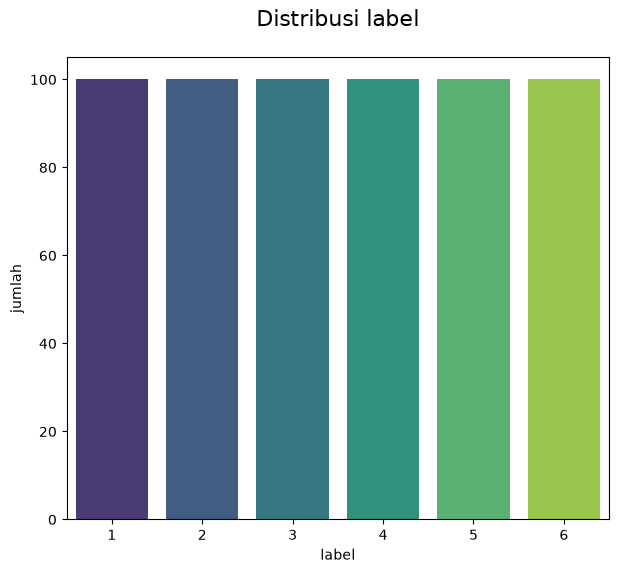

In [44]:
plt.figure(figsize=(7, 6))

sns.countplot(x='label', data=df, palette='viridis')
plt.title('Distribusi label', fontsize=16, y=1.05)
plt.xlabel('label')
plt.ylabel('jumlah')
plt.show()

**Insigt**: Keseluruhan label memiliki 100 data, yang artinya dataset tidak mengalami class imbalance sehingga akurasi dan metrik evaluasi dapat dibandingkan dengan lebih adil.

### 3.5 Visualisasi Distribusi Frekuensi Teratas Dengan Barplot

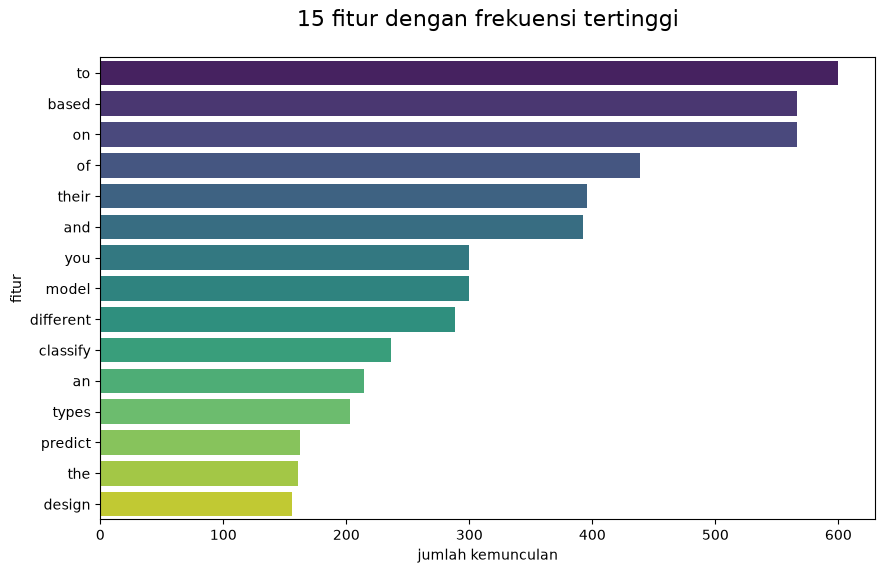

In [45]:
plt.figure(figsize=(10, 6))

sns.barplot(x=top_frequency.values, y=top_frequency.index, palette='viridis', hue=top_frequency.index)
plt.title('15 fitur dengan frekuensi tertinggi', fontsize=16, y=1.05)
plt.xlabel('jumlah kemunculan')
plt.ylabel('fitur')
plt.show()

**Insigt**: beberapa fitur seperti `to`, `based`, dan `on` paling sering muncul. Sehingga, sebagian terlalu umum untuk membedakan kelas.

### 3.6 Visualisasi Distribusi Frekuensi Terbawah dengan Barplot

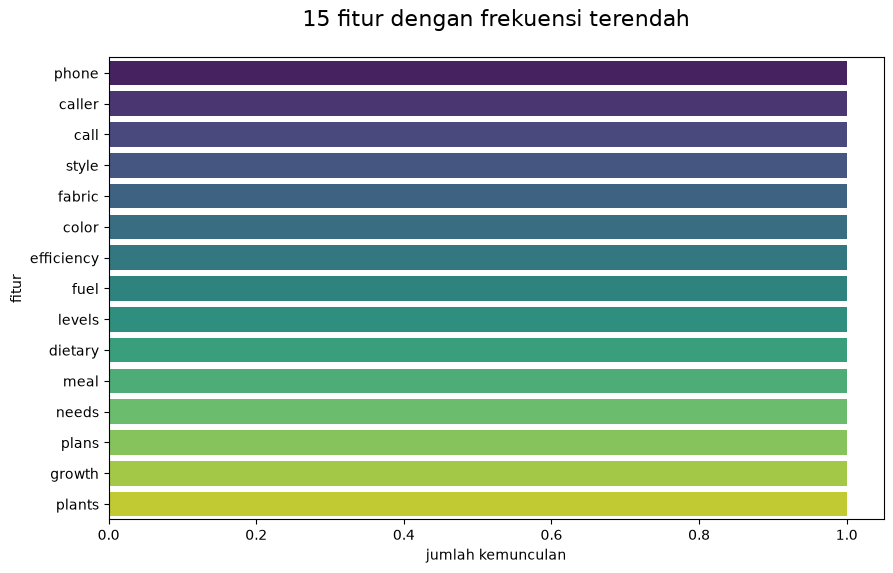

In [46]:
plt.figure(figsize=(10, 6))

sns.barplot(x=bottom_frequency.values, y=bottom_frequency.index, palette='viridis', hue=bottom_frequency.index)
plt.title('15 fitur dengan frekuensi terendah', fontsize=16, y=1.05)
plt.xlabel('jumlah kemunculan')
plt.ylabel('fitur')
plt.show()

**Insigt**: Fitur dengan frekuensi terendah dalam dataset dalam dataset, sehingga kontribusinya terhadap prediksi terbatas.

### 3.7 Visualisasi Fitur Paling Informatif Terhadap Label

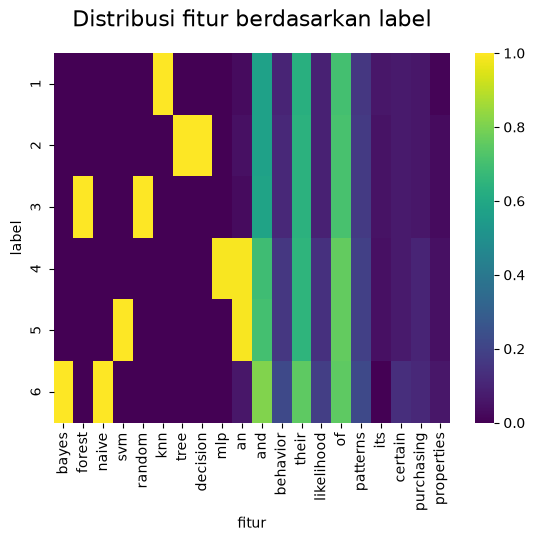

In [47]:
features_by_label = df.groupby('label').mean()
top_frequency = (features_by_label.max() - features_by_label.min()).sort_values(ascending=False).head(20).index

sns.heatmap(features_by_label[top_frequency], cmap='viridis')
plt.title('Distribusi fitur berdasarkan label', fontsize=16, y=1.05)
plt.xlabel('fitur')
plt.ylabel('label')
plt.show()

**Insigt**: Fitur seperti `bayes`, `forest`, `naive`, `smv`,  dan `knn` memiliki pola yang berbeda pada setiap label. FItur-fitur tersebut berpontensi membantu model.

---

## 4. Data PreProcessing

### 4.1 Memeriksa Missing Value dan Duplikat Data -> Menghapus Missing Value dan Duplikat Data Jika Tersedia

In [48]:
df.isnull().sum().sum()

np.int64(0)

In [49]:
df.duplicated().sum()

np.int64(210)

In [50]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

df.duplicated().sum()

np.int64(0)

### 4.2 Memisahkan Kolom Fitur ($X$) dan Kolom Target ($y$)

In [51]:
X = df.drop(columns=['label'])
y = df['label']

print(f"Bentuk X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"Bentuk Y : {len(y)} label")

Bentuk X : 390 baris, 333 kolom
Bentuk Y : 390 label


### 4.3 Memeriksa Nilai Negatif pada Kolom Fitur ($X$) & Melihat Nilai Terkecil dan Nilai Terbesar pada Kolom Fitur

In [52]:
nilai_negatif = (X < 0).any().any()
if nilai_negatif:
    print("Ditemukan nilai negatif pada fitur")
else:
    print("Semua nilai fitur bernilai non-negatif")

print(f"Nilai Terkecil : {X.values.min()}")
print(f"Nilai Terbesar : {X.values.max()}")

Semua nilai fitur bernilai non-negatif
Nilai Terkecil : 0
Nilai Terbesar : 1


### 4.4 Membagi Data Latih (80%) dan Data Uji (20%) 

In [53]:
np.random.seed(43)

indeks_acak = np.random.permutation(len(X))
batas = int(0.8 * len(X))

X_train = X.iloc[indeks_acak[:batas]].reset_index(drop=True)
X_test = X.iloc[indeks_acak[batas:]].reset_index(drop=True)

y_train = y.iloc[indeks_acak[:batas]].reset_index(drop=True)
y_test = y.iloc[indeks_acak[batas:]].reset_index(drop=True)

print(f"Data Latih  : {len(X_train)} baris (80%)")
print(f"Data Uji    : {len(X_test)} baris (20%)")

Data Latih  : 312 baris (80%)
Data Uji    : 78 baris (20%)


### 4.5 Menangani Input Teks Baru untuk GUI

In [54]:
daftar_fitur =  X.columns.tolist()

def ubah_teks(teks_input):
    teks_bersih = ''.join([huruf.lower() if huruf.isalnum() else '' for huruf in teks_input])
    daftar_kata = teks_bersih.split()

    vektor_kata = {kata: 0 for kata in daftar_fitur}
    for kata in daftar_kata:
        if kata in vektor_kata:
            vektor_kata[kata] += 1

    return pd.DataFrame([vektor_kata])

---

## 5. Modelling Naive Bayes (Multinomial)

### 5.1 Menghitung Probabilitas Prior

In [55]:
total = len(y_train)
jumlah_kelas = y_train.value_counts().sort_index()
prior = jumlah_kelas / total

for kelas, nilai in prior.items():
    print(f"Prior Kelas {kelas}: {nilai:.4f}")

Prior Kelas 1: 0.2212
Prior Kelas 2: 0.2115
Prior Kelas 3: 0.2019
Prior Kelas 4: 0.1410
Prior Kelas 5: 0.1250
Prior Kelas 6: 0.0994


### 5.2 Menghitung Probabilitas Likelihood

In [56]:
V = X_train.shape[1]
likelihood = {}

for kelas in prior.index:
    data_kelas = X_train[y_train == kelas]
    frek_kata = data_kelas.sum(axis=0)
    total_kata = data_kelas.values.sum()
    likelihood[kelas] = (frek_kata + 1) / (total_kata + V)

df_likelihood = pd.DataFrame(likelihood)
print("Contoh Nilai Likelihood untuk 5 Kata Pertama: ")
print(df_likelihood.head())

Contoh Nilai Likelihood untuk 5 Kata Pertama: 
              1         2         3         4         5         6
to     0.046823  0.044341  0.043866  0.039683  0.038647  0.034820
based  0.042809  0.040371  0.040439  0.035273  0.034783  0.031556
on     0.042809  0.040371  0.040439  0.035273  0.034783  0.031556
of     0.034114  0.032429  0.032214  0.031746  0.029952  0.025027
their  0.029431  0.026473  0.026731  0.024691  0.022222  0.023939


### 5.3 Menghitung Posterior 

In [57]:
def tebakan(baris_kata):
    skor = {}

    for kelas in prior.index:
        prior_ket = np.log(prior[kelas])
        likelihood_ket = np.sum(baris_kata * np.log(df_likelihood[kelas]))
        skor[kelas] = prior_ket + likelihood_ket

    return max(skor, key=skor.get)

y_pred = [tebakan(baris) for _, baris in X_test.iterrows()]
y_pred = pd.Series(y_pred, index=X_test.index)

print("Contoh 10 Hasil Tebakan Model: ", y_pred.head(10).tolist())
print("Contoh 10 Kunci Jawaban Asli : ", y_test.head(10).tolist())

Contoh 10 Hasil Tebakan Model:  [4, 2, 3, 1, 5, 4, 6, 1, 2, 1]
Contoh 10 Kunci Jawaban Asli :  [4, 2, 3, 1, 5, 5, 6, 1, 2, 1]


---

## 6. Evaluation

### 6.1 Menghitung Accuracy, Precision, Recall, F1-Score pada Model Naive Bayes (Multinomial)

In [58]:
prediksi_benar = (y_pred == y_test).sum()
total_data_uji = len(y_test)
skor_akurasi = (prediksi_benar / total_data_uji) 

print(f"Jumlah Prediksi Benar   : {prediksi_benar} dari {total_data_uji}")
print(f"Hasil Accuracy Model     : {skor_akurasi:.2%}\n")

table_eval = []

for kelas in prior.index:
    tp = ((y_pred == kelas) & (y_test == kelas)).sum()
    total_tebakan = (y_pred == kelas).sum()
    total_asli = (y_test == kelas).sum()

    precision = tp / total_tebakan
    recall = tp / total_asli
    f1_score = ((2 * precision * recall) / (precision + recall))

    table_eval.append({"Kelas": f"Kelas {kelas}", "Precision": f"{precision:.2f}", "Recall": f"{recall:.2f}", "F1-Score": f"{f1_score:.2f}", "Jumlah Asli": total_asli})

df_eval = pd.DataFrame(table_eval)
print(df_eval.to_string(index=False))

Jumlah Prediksi Benar   : 70 dari 78
Hasil Accuracy Model     : 89.74%

  Kelas Precision Recall F1-Score  Jumlah Asli
Kelas 1      1.00   0.94     0.97           16
Kelas 2      1.00   1.00     1.00           11
Kelas 3      1.00   1.00     1.00           14
Kelas 4      0.69   0.85     0.76           13
Kelas 5      0.86   0.71     0.77           17
Kelas 6      0.88   1.00     0.93            7


### 6.2 Visualisasi Evaluasi Confusion Matrix dan Perbandingan Metrik Evaluasi Model

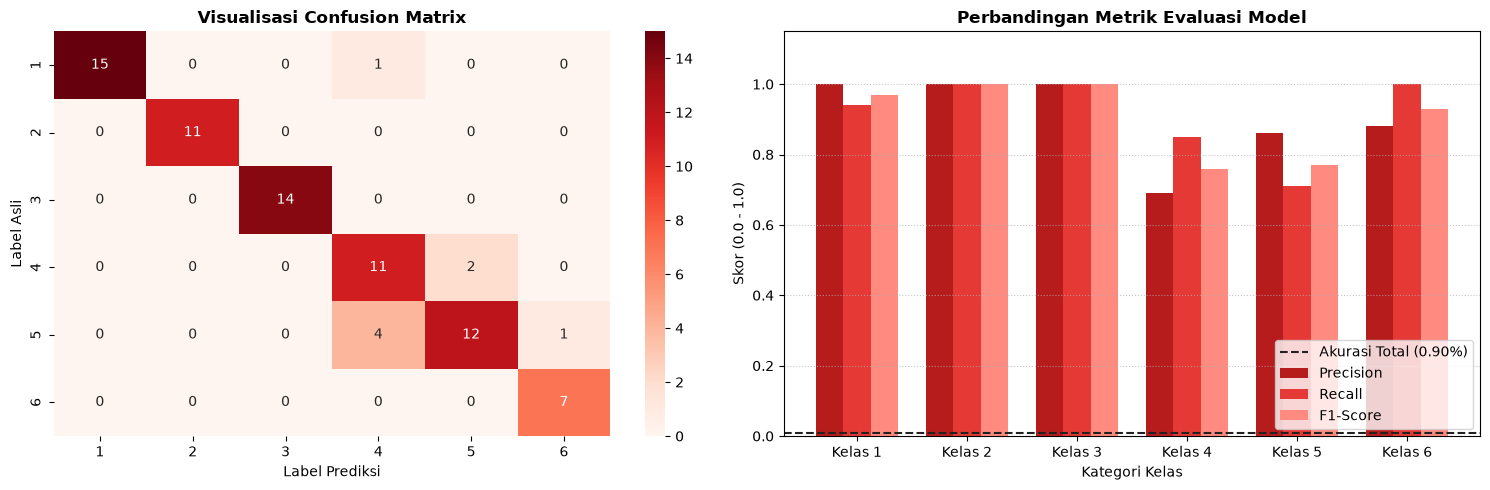

In [59]:
confusion_matrix = pd.crosstab(y_test, y_pred)

kelas = df_eval['Kelas']
precision = df_eval['Precision'].astype(float)
recall = df_eval['Recall'].astype(float)
f1 = df_eval['F1-Score'].astype(float)
posisi = np.arange(len(kelas))
lebar = 0.25

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Reds', ax=axes[0])
axes[0].set_title("Visualisasi Confusion Matrix", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Label Prediksi")
axes[0].set_ylabel("Label Asli")
axes[1].bar(posisi - lebar, precision, width=lebar, label='Precision', color='#B71C1C')
axes[1].bar(posisi, recall, width=lebar, label='Recall', color='#E53935')
axes[1].bar(posisi + lebar, f1, width=lebar, label='F1-Score', color='#FF8A80')

skor_akurasi_desimal = skor_akurasi / 100
axes[1].axhline(skor_akurasi_desimal, color='#212121', linestyle='--', linewidth=1.5,
                label=f'Akurasi Total ({skor_akurasi:.2f}%)')

axes[1].set_title("Perbandingan Metrik Evaluasi Model", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Kategori Kelas")
axes[1].set_ylabel("Skor (0.0 - 1.0)")
axes[1].set_xticks(posisi)
axes[1].set_xticklabels(kelas)
axes[1].set_ylim(0, 1.15)
axes[1].legend(loc='lower right')
axes[1].grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

---

## 7. GUI

In [64]:
def tebakan(vektor_kata):
    skor = {}

    for kelas in prior.index:
        prior_ket = np.log(prior[kelas])
        likelihood_ket = np.sum(vektor_kata * np.log(df_likelihood[kelas]))
        skor[kelas] = prior_ket + likelihood_ket

    return max(skor, key=skor.get)

def cek_data_baru() :
    teks_input = entry_data.get("1.0", tk.END).strip().lower()
    
    if not teks_input:
        label_hasil.configure(text="Hasil Prediksi: Masukkan teks terlebih dahulu.")
        return
    
    kata_input = teks_input.split()
    
    vektor_kata = np.zeros(len(daftar_fitur))
    for i, kata in enumerate(daftar_fitur) :
        if kata in kata_input:
            vektor_kata[i] = 1

    try :
        prediksi_label = tebakan(vektor_kata)
        label_hasil.configure(text=f"Hasil Prediksi: {prediksi_label}")
    except Exception as e:
        label_hasil.configure(text=f"Hasil Prediksi: Terjadi kesalahan - {str(e)}")


In [65]:
import tkinter as tk
from customtkinter import *

app = CTk()
app.title("Prediksi Naive Bayes Multinominal")
app.geometry("700x600")
app.config(bg="#1e1e1e")

judul = tk.Label(app, text="Prediksi Naive Bayes Mutinominal", font=("Arial", 24, "bold"), fg="white", bg="#1e1e1e")
judul.pack(pady=20)

deskripsi = tk.Label(app, text="Naive Bayes Multinominal", font=("Arial", 10), fg="white", bg="#1e1e1e")
deskripsi.pack()

entry_data = CTkTextbox(master=app, width=500, height=200, font=("Arial", 12), fg_color="white", text_color="black", corner_radius=12, border_color="gray", border_width=1)
entry_data.place(x=350, y=250, anchor="center")

label_hasil = CTkLabel(master=app, text="Hasil Prediksi:...", font=("Arial", 12, "bold"), fg_color="white", text_color="black", corner_radius=12, width=500, height=50,)
label_hasil.place(x=350, y=400, anchor="center")

enter_data = CTkButton(master=app, text="Kirim Teks", command=cek_data_baru, corner_radius=32, fg_color="blue")
enter_data.place(x=350, y=474, anchor="center")

app.mainloop()

---

## 8. Conclusion

### 8.1 Kesimpulan Analisis dan Permodelan

Berdasarkan seluruh tahapan analisis data, *preprocessing*, pemodelan, hingga evaluasi yang telah dilakukan, dapat ditarik beberapa kesimpulan utama sebagai berikut:

1. Model klasifikasi menggunakan algoritma **Multinomial Naive Bayes** berhasil memberikan solusi dalam mengelompokkan dokumen dan deskripsi studi kasus ke dalam 6 kategori label. Sistem ini juga telah diintegrasikan ke dalam **GUI** sehingga pengguna dapat melakukan prediksi dokumen baru secara praktis tanpa proses manual.

2. Dataset awal terdiri dari **600 baris dan 334 kolom**. Dataset tidak memiliki *missing value*, namun ditemukan **210 baris data duplikat**. Setelah dilakukan pembersihan duplikat, diperoleh **390 baris data bersih** yang dibagi menjadi **312 data latih (80%)** dan **78 data uji (20%)**. Berdasarkan hasil *Exploratory Data Analysis* (EDA), kata-kata umum seperti `to`, `based`, dan `on` muncul hampir di seluruh dokumen, sedangkan istilah teknis spesifik seperti `bayes`, `forest`, `naive`, `smv`, dan `knn` menjadi fitur pembeda antar kelas.

3. Pengujian model menggunakan perhitungan *Prior*, *Likelihood*, dan *Posterior* berhasil memprediksi **70 dari 78 dokumen uji dengan benar**, menghasilkan **Akurasi sebesar 89.74%**. **Kelas 2 dan Kelas 3** mencatatkan performa sempurna dengan nilai *Precision*, *Recall*, dan *F1-Score* masing-masing sebesar **1.00**, diikuti oleh **Kelas 1** dan **Kelas 6**. **Kelas 4** dan **Kelas 5** menunjukkan performa yang cukup baik meskipun terdapat beberapa kesalahan prediksi akibat kemiripan distribusi kata di antara kedua kelas tersebut.